# sub-16: decoding the bars stimulus from the data (subject-specific decoder)

**Why the previous searches stayed ambiguous**: they predict the response from the pRF model (pRF estimates, fixed HRF, CSS exponent). Model errors make several sequences fit almost equally well (2-3 swapped sweeps out of 10).

**New approach, without the pRF model**: a decoder learned on the **runs of sub-16 itself whose stimulus is known** (Rings and Wedges of both eyes, plus BarsLeftEye run-02 = A). It learns directly, for this subject, how the stimulus image at time t maps onto the cortical activity at t+1 … t+4 TR, with its real HRF and its real vertices. It is a ridge regression (kernel form), with the penalty chosen by leave-one-run-out. Applied to a run whose stimulus is unknown, it gives a **decoded movie** of the stimulus.

**Then**: exact search (dynamic programming, no beam) of the best chain of events in the decoded movie. The events are sweeps in one of the 8 directions, or blanks of any length, with no constraint on order or number of blanks. The sweep **duration** is also tested (10 to 14 TR), in case the pilot used another period.

**Validation** (the decoder never sees the tested run):
1. sub-16 BarsLeftEye run-02 decoded with a decoder trained only on Rings/Wedges. The chain must be A, exactly.
2. Controls: sub-13 (A) and sub-17 (B), decoded with a decoder trained on their Rings/Wedges + their other bars run.
3. Null: a rings run of sub-16 (no bar): low sweep scores.
4. **Independent check**: the decoded chain is scored with the pRF model, on vertex data. It is compared with A, B and the v2 chain (`sub16_recovered_mgl_v2`).

Variants tested on validation 1: vertices of V1-V3, or all ROIs; up to 3000 or 6000 best vertices (mean R² of the two eyes' Rings/Wedges pRFs). The best variant is kept.

Other subjects cannot help decode sub-16 (different cortical surfaces); they serve as controls of the method. Read only. Outputs in `Desktop/fig_od/sub16_decoder/`.

In [1]:
import os, glob, math
import numpy as np, pandas as pd, nibabel as nb
import scipy.io as sio
import matplotlib.pyplot as plt

main = '/Users/uriel/disks/meso_shared/amblyo7T_prf'
pp = f'{main}/derivatives/pp_data'
out_dir = '/Users/uriel/Desktop/fig_od/sub16_decoder'
os.makedirs(out_dir, exist_ok=True)
TR = 2.0
lags = [1, 2, 3, 4]                       # data at t+lag decodes the stimulus at t
alphas = [1e1, 1e2, 1e3, 1e4, 1e5, 1e6]
sweep_lengths = [10, 11, 12, 13, 14]
variants = {'V1-V3, 3000': ([1, 2, 3], 3000), 'V1-V3, 6000': ([1, 2, 3], 6000),
            'all ROIs, 3000': (None, 3000), 'all ROIs, 6000': (None, 6000)}
RW = ['RingsLeftEye_run-01', 'WedgesLeftEye_run-01', 'RingsRightEye_run-01', 'WedgesRightEye_run-01']

/var/folders/60/q71xm4hx45x3db5d6mzl8r4h0000gn/T/ipykernel_5943/642900179.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import numpy as np, pandas as pd, nibabel as nb


## Stimuli and templates

In [2]:
def build_vdm(mat_fn):
    """Same conversion as create_vdm_files.ipynb (50 x 50, transposed, padded)."""
    im = np.asarray(sio.loadmat(mat_fn, squeeze_me=True, struct_as_record=False)['s'].im, float)
    out = np.zeros((50, 50, im.shape[-1]))
    ii = np.floor(np.arange(50) * 102 / 50).astype(int)
    for t in range(im.shape[-1]):
        f = (im[..., t] * 255).astype(np.uint8).T
        sq = np.vstack([np.zeros((12, 102), np.uint8), f, np.zeros((13, 102), np.uint8)])
        out[..., t] = (sq > 5)[np.ix_(ii, ii)]
    return out

vdm = {eye: np.load(f'{main}/derivatives/vdm/task-BarsBarsRingsWedges{eye}_vdm.npy') for eye in ['LeftEye', 'RightEye']}
A = vdm['LeftEye'][..., :120]
B = build_vdm(f'{main}/sourcedata/C/jp/cond-1-stim-3.mat')
true_stim = {'A': A, 'B': B}


def run_stim(r, kind=None):
    """Known stimulus (50,50,120) of a run."""
    eye = 'LeftEye' if 'LeftEye' in r else 'RightEye'
    if r.startswith('Rings'): return vdm[eye][..., 240:360]
    if r.startswith('Wedges'): return vdm[eye][..., 360:480]
    return true_stim[kind]


def ds(st):
    """(50,50,T) -> (T, 625), 2x2 average."""
    return st.reshape(25, 2, 25, 2, -1).mean((1, 3)).reshape(625, -1).T

rr, cc = np.meshgrid(np.arange(50) - 24.5, np.arange(50) - 24.5, indexing='ij')
X_pix, Y_pix = cc, -rr


def frame_label(f):
    m = f > 0
    if m.sum() < 3: return None, np.nan
    best = None
    for a in [0, 45, 90, 135]:
        th = np.deg2rad(a); p = X_pix[m] * np.cos(th) + Y_pix[m] * np.sin(th)
        if best is None or p.std() < best[0]: best = (p.std(), a, p.mean())
    return best[1], best[2]


def segment(stim):
    lab = [frame_label(stim[..., t]) for t in range(stim.shape[-1])]
    ev, t = [], 0
    while t < len(lab):
        o, p = lab[t]; u = t + 1
        if o is None:
            while u < len(lab) and lab[u][0] is None: u += 1
            ev.append(('b', t, u - t))
        else:
            while u < len(lab) and lab[u][0] == o and u - t < 12: u += 1
            ev.append((f"{o}{'+' if lab[u - 1][1] > p else '-'}", t, u - t))
        t = u
    return ev

templates = {}
for stim in [A, B]:
    for k, s, l in segment(stim):
        if k != 'b' and l == 12 and k not in templates:
            templates[k] = stim[..., s:s + 12]
print(sorted(templates))


def tmpl(k, L):
    """Sweep k resampled to L frames, full resolution (50,50,L)."""
    return templates[k][..., np.round(np.linspace(0, 11, L)).astype(int)]


def chain_to_stim(chain):
    st = np.zeros((50, 50, 120))
    for k, t0, L in chain:
        if k == 'b': continue
        fr = tmpl(k, L)
        n = min(L, 120 - t0)
        st[..., t0:t0 + n] = fr[..., :n]
    return st


def chain_str(chain):
    return ' '.join(f'b{L}' if k == 'b' else (k if L == 12 else f'{k}/{L}') for k, t0, L in chain)

true_chain = {k: [(e[0], e[1], e[2]) for e in segment(v)] for k, v in true_stim.items()}
print('A:', chain_str(true_chain['A'])); print('B:', chain_str(true_chain['B']))

['0+', '0-', '135+', '135-', '45+', '45-', '90+', '90-']
A: b6 135+ 90+ b5 45- 0+ 135- 0- 45+ 90- 135- 135-/1
B: 0+ 135- 90- 45- 0- 135+ 90+ 45+ 0+ 135-


## Data and vertex selection

In [3]:
cache = {}
def load_subject(s):
    if s in cache: return cache[s]
    roi = np.concatenate([nb.load(glob.glob(f'{pp}/{s}/fsnative/rois/{s}_hemi-{h}_fmriprep_dct_*_rois-group-mmp.func.gii')[0]).darrays[0].data
                          for h in ['L', 'R']])
    prf = {eye: np.hstack([np.vstack([a.data for a in nb.load(
        f'{pp}/{s}/fsnative/prfmodel/prf_derivatives/{s}_task-RingsWedges{eye}_hemi-{h}_fmriprep_dct_psc_concat_prf-css_deriv.func.gii').darrays])
        for h in ['L', 'R']]) for eye in ['LeftEye', 'RightEye']}
    cache[s] = (roi, prf)
    return cache[s]

run_cache = {}
def load_run(s, r):
    if (s, r) in run_cache: return run_cache[(s, r)]
    hs = []
    for h in ['L', 'R']:
        d = np.vstack([a.data for a in nb.load(
            f'{pp}/{s}/fsnative/func/fmriprep_dct_psc/{s}_ses-01_task-{r}_hemi-{h}_space-fsnative_fmriprep_dct_psc_bold.func.gii').darrays])
        hs.append(d if d.shape[0] == 120 else d.T)
    run_cache[(s, r)] = np.hstack(hs).astype(np.float32)
    return run_cache[(s, r)]


def select_vertices(s, rois, n_max):
    roi, prf = load_subject(s)
    r2 = (prf['LeftEye'][0] + prf['RightEye'][0]) / 2
    ok = np.isfinite(r2) & (r2 > 0.1) & ((roi > 0) if rois is None else np.isin(roi, rois))
    idx = np.where(ok)[0]
    return idx[np.argsort(-r2[idx])[:n_max]]


def zc(a, axis=0):
    a = a - a.mean(axis, keepdims=True)
    return a / (a.std(axis, keepdims=True) + 1e-9)


def features(y):
    """(120, nv) -> (120, nv * n_lags): row t = data at t+lag."""
    y = zc(np.nan_to_num(y))
    cols = []
    for l in lags:
        z = np.zeros_like(y); z[:120 - l] = y[l:]
        cols.append(z)
    return np.hstack(cols) / np.sqrt(y.shape[1] * len(lags))

## Decoder (kernel ridge, penalty and gain by leave-one-run-out)

In [4]:
def frame_corr(D, S):
    """Median over non-blank frames of the correlation between decoded and true frames."""
    m = S.sum(1) > 0
    Dc = D[m] - D[m].mean(1, keepdims=True); Sc = S[m] - S[m].mean(1, keepdims=True)
    return float(np.median((Dc * Sc).sum(1) / (np.sqrt((Dc ** 2).sum(1) * (Sc ** 2).sum(1)) + 1e-9)))


def fit_predict(Xtr, Ytr, Xte, alpha):
    mu = Ytr.mean(0)
    K = Xtr @ Xtr.T
    W = np.linalg.solve(K + alpha * np.eye(len(K)), Ytr - mu)
    return Xte @ Xtr.T @ W + mu


def train_decoder(train):
    """train: list of (X, Y). Returns predict(X), chosen alpha, gain, LORO frame corr."""
    best = None
    for a in alphas:
        preds = [fit_predict(np.vstack([t[0] for j, t in enumerate(train) if j != i]),
                             np.vstack([t[1] for j, t in enumerate(train) if j != i]), train[i][0], a) for i in range(len(train))]
        sc = np.mean([frame_corr(p, t[1]) for p, t in zip(preds, train)])
        if best is None or sc > best[0]:
            best = (sc, a, preds)
    sc, a, preds = best
    P, Y = np.vstack(preds), np.vstack([t[1] for t in train])
    mu = Y.mean(0)
    gain = float(((P - mu) * (Y - mu)).sum() / ((Y - mu) ** 2).sum())   # shrinkage of the decoded amplitude
    Xtr, Ytr = np.vstack([t[0] for t in train]), np.vstack([t[1] for t in train])
    return (lambda X: fit_predict(Xtr, Ytr, X, a)), a, gain, sc, mu

## Exact search of the chain in the decoded movie (dynamic programming)

In [5]:
def best_chain(D, gain, mu, L):
    """D (120, 625) decoded movie. Events: sweeps (8 directions, L frames, may be cut by the end of the run) or blanks (1..14 TR).
    Frame score = -(|| (D - mu) - gain * (f - mu) ||^2 - || (D - mu) + gain * mu ||^2 ), i.e. improvement over a blank frame."""
    T = len(D)
    Dc = D - mu
    blank_err = ((Dc + gain * mu) ** 2).sum(1)                                  # error if the frame is blank
    sc = {}
    for k in templates:
        F = ds(tmpl(k, L))                                                      # (L, 625)
        err = ((Dc[:, None, :] - gain * (F - mu)[None]) ** 2).sum(2)            # (T, L)
        gainf = blank_err[:, None] - err                                        # > 0 if the frame looks like this template frame
        sc[k] = np.array([sum(gainf[t0 + i, i] for i in range(L) if t0 + i < T) for t0 in range(T)])
    best = np.full(T + 1, -np.inf); best[0] = 0; back = [None] * (T + 1)
    final = (-np.inf, None)
    for t in range(T):
        if not np.isfinite(best[t]): continue
        for b in range(1, 15):
            u = min(T, t + b)
            if best[t] > best[u] - 1e-12 and (back[u] is None or best[t] > best[u]):
                best[u] = best[t]; back[u] = (t, 'b', b)
        for k in templates:
            v = best[t] + sc[k][t]
            u = t + L
            if u <= T:
                if v > best[u]: best[u] = v; back[u] = (t, k, L)
            elif v > final[0]:
                final = (v, (t, k, L))
    if best[T] >= final[0]:
        tot, u, chain = best[T], T, []
    else:
        tot, chain = final[0], [(final[1][1], final[1][0], final[1][2])]; u = final[1][0]
    while u > 0:
        t, k, l = back[u]; chain.append((k, t, l)); u = t
    chain = chain[::-1]
    # merge consecutive blanks
    merged = []
    for e in chain:
        if merged and e[0] == 'b' and merged[-1][0] == 'b':
            merged[-1] = ('b', merged[-1][1], merged[-1][2] + e[2])
        else:
            merged.append(e)
    # confidence of each sweep: margin over the 2nd best direction at the same place, relative to its own score
    conf = []
    for k, t0, l in merged:
        if k == 'b': continue
        alt = max(sc[k2][t0] for k2 in templates if k2 != k)
        conf.append((k, t0, sc[k][t0], (sc[k][t0] - alt) / (abs(sc[k][t0]) + 1e-9)))
    return merged, tot, conf


def same_order(c1, c2):
    a = [k for k, t, l in c1 if k != 'b']; b = [k for k, t, l in c2 if k != 'b']
    return a == b

## pRF-model check (independent of the decoder)

In [6]:
pix = 2 * math.degrees(math.atan(50.6 / 2 / 242)) / 50
Xd, Yd = X_pix * pix, Y_pix * pix
t_ = np.arange(0, 32, TR)
g = lambda a: t_ ** (a - 1) * np.exp(-t_) / math.gamma(a)
H = g(6) - g(16) / 6; H /= H.sum()
N_fft = 256
Hf = np.fft.rfft(H, n=N_fft)


def conv_hrf(d):
    return np.fft.irfft(np.fft.rfft(d, n=N_fft, axis=0) * Hf[:, None], n=N_fft, axis=0)[:d.shape[0]]


def prf_score(stim, s, r):
    """Median correlation (V1-V3 vertices, pRFs of the eye) between data and pRF prediction, best delay -2..+2 TR."""
    roi, prf = load_subject(s)
    D = prf['LeftEye' if 'LeftEye' in r else 'RightEye']
    y = load_run(s, r)
    idx = np.where((D[0] > 0.2) & (D[1] < 6) & np.isin(roi, [1, 2, 3]) & np.isfinite(y).all(0) & (y.std(0) > 0))[0]
    x0, y0, sd, n = D[7][idx], D[8][idx], np.clip(D[4][idx], 0.2, None), np.clip(D[11][idx], 0.05, 1)
    G = np.exp(-((Xd.ravel()[:, None] - x0) ** 2 + (Yd.ravel()[:, None] - y0) ** 2) / (2 * sd ** 2))
    p = conv_hrf(np.clip(np.moveaxis(stim, -1, 0).reshape(120, -1) @ G, 0, None) ** n)
    yy = y[:, idx]
    best = -np.inf
    for sh in range(-2, 3):
        q = np.roll(p, sh, 0)
        if sh > 0: q[:sh] = p[0]
        elif sh < 0: q[sh:] = p[-1]
        best = max(best, float(np.median((zc(q) * zc(yy)).mean(0))))
    return best

## Step 1 — choose the variant on the validation run (sub-16 BarsLeftEye run-02, decoder trained on Rings/Wedges only)

In [7]:
def make_set(s, runs_kinds, idx):
    return [(features(load_run(s, r)[:, idx]), ds(run_stim(r, k))) for r, k in runs_kinds]

val_rows = []
for vname, (rois, nmax) in variants.items():
    idx = select_vertices('sub-16', rois, nmax)
    pred, a, gain, loro, mu = train_decoder(make_set('sub-16', [(r, None) for r in RW], idx))
    D = pred(features(load_run('sub-16', 'BarsLeftEye_run-02')[:, idx]))
    res = {'variant': vname, 'n vertices': len(idx), 'alpha': a, 'LORO frame corr (train)': loro,
           'frame corr vs A': frame_corr(D, ds(A)), 'frame corr vs B': frame_corr(D, ds(B))}
    for L in [12]:
        ch, tot, conf = best_chain(D, gain, mu, L)
        res['chain'] = chain_str(ch); res['order = A'] = same_order(ch, true_chain['A'])
        res['min sweep confidence'] = min(c_[3] for c_ in conf) if conf else np.nan
    val_rows.append(res)
    print(vname, 'done', flush=True)
val = pd.DataFrame(val_rows).set_index('variant')
pd.set_option('display.max_colwidth', 200)
best_variant = val['frame corr vs A'].idxmax()
print('true A:', chain_str(true_chain['A']))
print('kept variant:', best_variant)
val

V1-V3, 3000 done
V1-V3, 6000 done
all ROIs, 3000 done
all ROIs, 6000 done
true A: b6 135+ 90+ b5 45- 0+ 135- 0- 45+ 90- 135- 135-/1
kept variant: V1-V3, 3000


,n vertices,alpha,LORO frame corr (train),frame corr vs A,frame corr vs B,chain,order = A,min sweep confidence
variant,,,,,,,,
"V1-V3, 3000",3000,10.0,0.827022,0.385393,0.201169,b5 135+ b17 0- 0+ 135- 0- 0+ 45- 135- b2,False,0.210683
"V1-V3, 6000",6000,10.0,0.824515,0.383952,0.204808,b5 135+ b18 0- 0+ 135- 0- 0+ 90- 0+ b1,False,0.154295
"all ROIs, 3000",3000,10.0,0.826392,0.384280,0.201573,b5 135+ b17 0- 0+ 135- 0- 0+ 45- 135- b2,False,0.203596
"all ROIs, 6000",6000,10.0,0.824135,0.382529,0.205542,b5 135+ b18 0- 0+ 135- 0- 0+ b11 135- b2,False,0.162015


## Step 2 — controls, null and suspect runs

For each run, the decoder is trained on all the runs of the subject with a known stimulus, except the decoded run.

In [8]:
rois, nmax = variants[best_variant]
cases = [  # subject, decoded run, true stimulus, training runs (run, kind)
    ('sub-16', 'BarsLeftEye_run-02', 'A', [(r, None) for r in RW]),
    ('sub-13', 'BarsLeftEye_run-01', 'A', [(r, None) for r in RW] + [('BarsRightEye_run-02', 'A')]),
    ('sub-17', 'BarsLeftEye_run-01', 'B', [(r, None) for r in RW] + [('BarsRightEye_run-02', 'B')]),
    ('sub-16', 'RingsLeftEye_run-01', 'null (rings)', [(r, None) for r in RW if r != 'RingsLeftEye_run-01'] + [('BarsLeftEye_run-02', 'A')]),
    ('sub-16', 'BarsLeftEye_run-01', 'suspect', [(r, None) for r in RW] + [('BarsLeftEye_run-02', 'A')]),
    ('sub-16', 'BarsRightEye_run-01', 'suspect', [(r, None) for r in RW] + [('BarsLeftEye_run-02', 'A')]),
    ('sub-16', 'BarsRightEye_run-02', 'suspect', [(r, None) for r in RW] + [('BarsLeftEye_run-02', 'A')]),
]
v2_dir = '/Users/uriel/Desktop/fig_od/sub16_recovered_mgl_v2'
rows, decoded = [], {}
for s, r, kind, train in cases:
    idx = select_vertices(s, rois, nmax)
    pred, a, gain, loro, mu = train_decoder(make_set(s, train, idx))
    D = pred(features(load_run(s, r)[:, idx]))
    res = {'subject': s, 'run': r, 'true': kind, 'LORO frame corr (train)': loro}
    if kind in true_stim:
        res['frame corr vs true'] = frame_corr(D, ds(true_stim[kind]))
    by_L = {L: best_chain(D, gain, mu, L) for L in sweep_lengths}
    for L in sweep_lengths:
        res[f'score L={L}'] = by_L[L][1]
    L_best = max(sweep_lengths, key=lambda L: by_L[L][1])
    ch, tot, conf = by_L[L_best]
    res['best L'] = L_best
    res['chain'] = chain_str(ch)
    res['n sweeps'] = len(conf)
    res['n distinct directions'] = len({c_[0] for c_ in conf})
    res['median sweep confidence'] = float(np.median([c_[3] for c_ in conf])) if conf else np.nan
    res['min sweep confidence'] = float(min(c_[3] for c_ in conf)) if conf else np.nan
    if kind in true_stim:
        res['order = true'] = same_order(ch, true_chain[kind])
    stim_dec = chain_to_stim(ch)
    res['pRF score decoded chain'] = prf_score(stim_dec, s, r)
    res['pRF score A'] = prf_score(A, s, r)
    res['pRF score B'] = prf_score(B, s, r)
    fv2 = f'{v2_dir}/{s}_{r}_recovered_vdm.npy'
    if os.path.exists(fv2):
        v2 = np.load(fv2)
        res['pRF score v2 chain'] = prf_score(v2, s, r)
        res['frame corr decoded chain vs v2'] = float(np.corrcoef(stim_dec.ravel(), v2.ravel())[0, 1])
    decoded[(s, r)] = (D, ch, conf, stim_dec)
    np.save(f'{out_dir}/{s}_{r}_decoded_chain_vdm.npy', stim_dec)
    np.save(f'{out_dir}/{s}_{r}_decoded_movie.npy', D)
    rows.append(res)
    print(s, r, 'done', flush=True)
tab = pd.DataFrame(rows).set_index(['subject', 'run'])
print('true A:', chain_str(true_chain['A'])); print('true B:', chain_str(true_chain['B']))
tab[['true', 'best L', 'chain']]

sub-16 BarsLeftEye_run-02 done
sub-13 BarsLeftEye_run-01 done
sub-17 BarsLeftEye_run-01 done
sub-16 RingsLeftEye_run-01 done
sub-16 BarsLeftEye_run-01 done
sub-16 BarsRightEye_run-01 done
sub-16 BarsRightEye_run-02 done
true A: b6 135+ 90+ b5 45- 0+ 135- 0- 45+ 90- 135- 135-/1
true B: 0+ 135- 90- 45- 0- 135+ 90+ 45+ 0+ 135-


true  best L  \
subject run                                         
sub-16  BarsLeftEye_run-02              A      11   
sub-13  BarsLeftEye_run-01              A      12   
sub-17  BarsLeftEye_run-01              B      12   
sub-16  RingsLeftEye_run-01  null (rings)      12   
        BarsLeftEye_run-01        suspect      11   
        BarsRightEye_run-01       suspect      11   
        BarsRightEye_run-02       suspect      12   

                                                                                                                    chain  
subject run                                                                                                                
sub-16  BarsLeftEye_run-02                      b5 135+/11 b19 0-/11 b2 0+/11 135-/11 b2 0-/11 0+/11 45-/11 b2 135-/11 b2  
sub-13  BarsLeftEye_run-01                                                  b6 135+ 90+ b5 45- 0+ 135- 0- 45+ 90- 135- b1  
sub-17  BarsLeftEye_run-01                                                         0+ 135- 90- 45- 0- 135+ 90+ 0+ 0+ 135-  
sub-16  RingsLeftEye_run-01                                                           b8 0- b1 0- 0- 0- 0- 0- 0- 0- 0+ b3  
        BarsLeftEye_run-01     b6 90+/11 b1 0+/11 b6 45+/11 b1 135-/11 b1 45-/11 b1 135+/11 b1 90-/11 b2 135-/11 0-/11 b2  
        BarsRightEye_run-01  b6 135-/11 b1 0+/11 b1 135-/11 b1 45-/11 b1 135+/11 b1 90+/11 b6 0-/11 b1 0+/11 b1 90-/11 b2  
        BarsRightEye_run-02                                                  b5 135- 0- 0+ 135+ 45- b6 135- 90+ b12 0+ b1

In [9]:
cols = ['true', 'LORO frame corr (train)', 'frame corr vs true', 'order = true', 'best L', 'n sweeps', 'n distinct directions',
        'median sweep confidence', 'min sweep confidence', 'pRF score decoded chain', 'pRF score v2 chain', 'pRF score A', 'pRF score B',
        'frame corr decoded chain vs v2'] + [f'score L={L}' for L in sweep_lengths]
print(tab[[c_ for c_ in cols if c_ in tab.columns]].round(3).T.to_string())
print()
for (s, r), (D, ch, conf, _) in decoded.items():
    print(s, r, '| sweeps: direction, start TR, score, confidence (margin over 2nd direction / score)')
    print('   ' + '  '.join(f'{k}@{t0}:{sc_:.0f}/{cf:.2f}' for k, t0, sc_, cf in conf))

subject                                    sub-16             sub-13             sub-17              sub-16                                                           
run                            BarsLeftEye_run-02 BarsLeftEye_run-01 BarsLeftEye_run-01 RingsLeftEye_run-01 BarsLeftEye_run-01 BarsRightEye_run-01 BarsRightEye_run-02
true                                            A                  A                  B        null (rings)            suspect             suspect             suspect
LORO frame corr (train)                     0.827              0.742              0.749               0.631              0.743               0.743               0.743
frame corr vs true                          0.385              0.501               0.46                 NaN                NaN                 NaN                 NaN
order = true                                False              False              False                 NaN                NaN                 NaN                 Na

## Decoded movies

Every 2nd TR: decoded frame (top) and frame of the decoded chain (bottom), for each run. For the controls, the frames of the true stimulus are added.

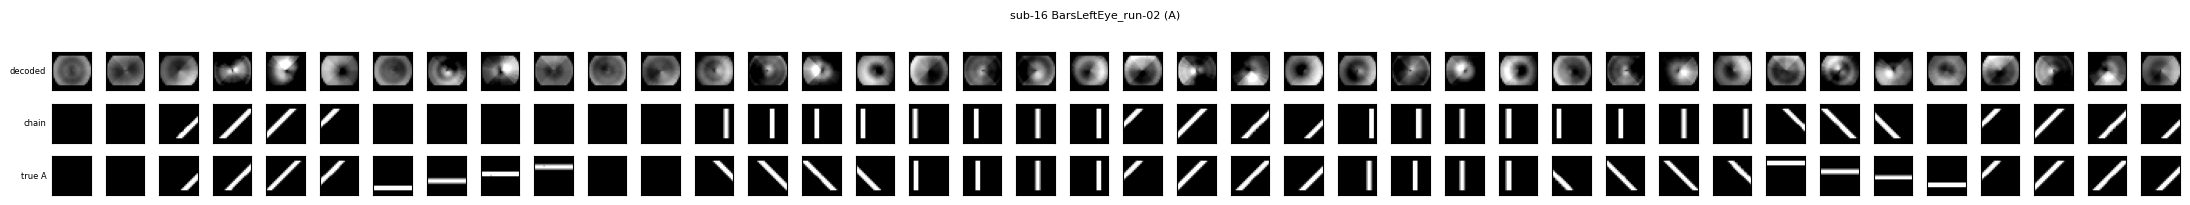

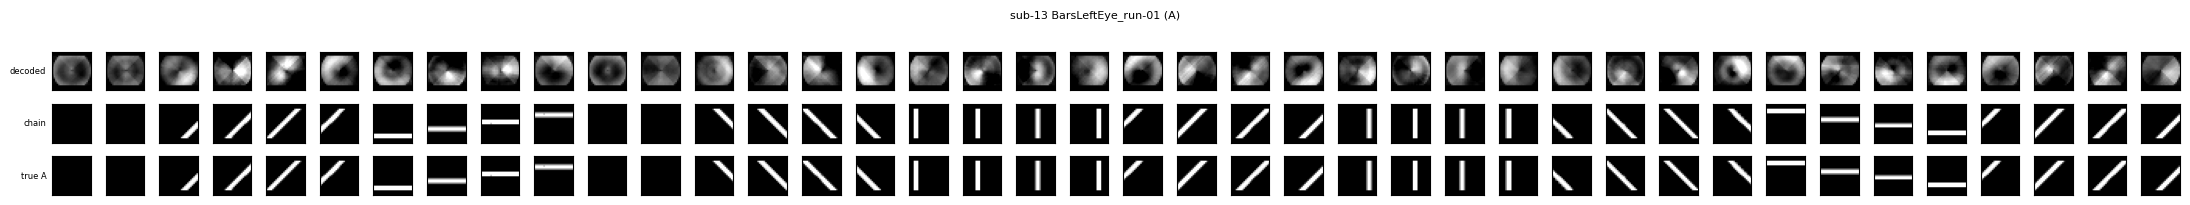

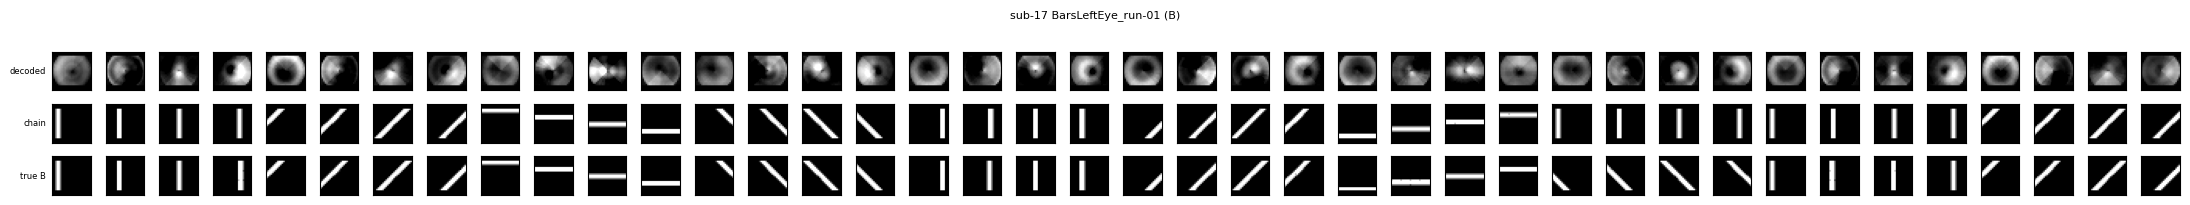

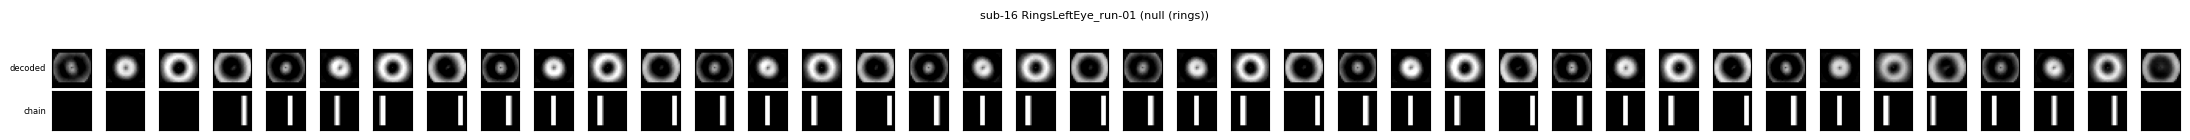

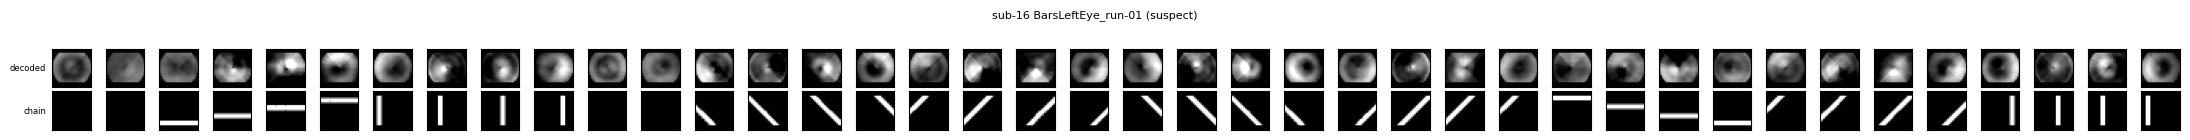

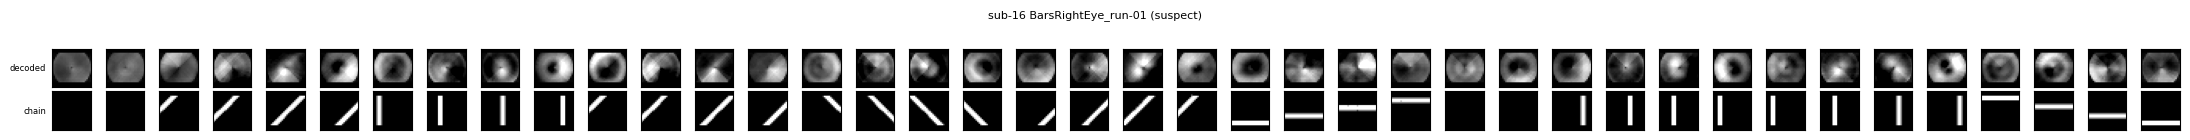

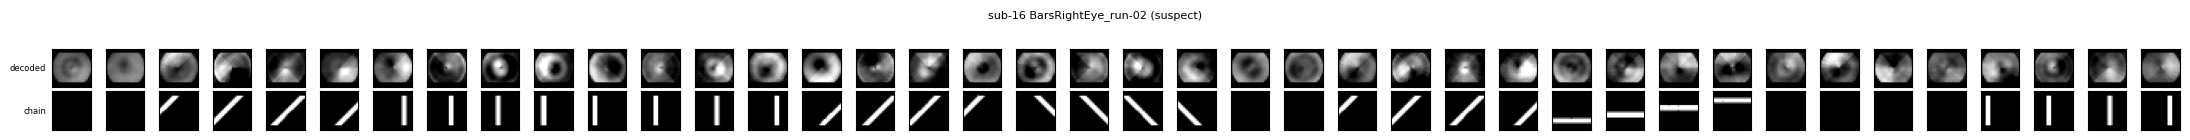

In [10]:
frames = list(range(0, 120, 3))
for (s, r), (D, ch, conf, stim_dec) in decoded.items():
    kind = tab.loc[(s, r), 'true']
    rows_ = [('decoded', D.reshape(-1, 25, 25)), ('chain', ds(stim_dec).reshape(-1, 25, 25))]
    if kind in true_stim: rows_.append(('true ' + kind, ds(true_stim[kind]).reshape(-1, 25, 25)))
    fig, axes = plt.subplots(len(rows_), len(frames), figsize=(len(frames) * 0.55, len(rows_) * 0.7))
    for i, (name, mov) in enumerate(rows_):
        for j, t in enumerate(frames):
            axes[i, j].imshow(mov[t], cmap='gray', vmin=0, vmax=max(1e-6, np.percentile(mov, 99.5)))
            axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        axes[i, 0].set_ylabel(name, fontsize=6, rotation=0, ha='right', va='center')
    fig.suptitle(f'{s} {r} ({kind})', fontsize=8)
    plt.tight_layout()
    fig.savefig(f'{out_dir}/{s}_{r}_decoded.pdf', bbox_inches='tight')
    plt.show()

## How to read

- **Step 1**: the decoder trained only on Rings/Wedges must recover the A chain of BarsLeftEye run-02 (order = A True). If it does, it can read sweeps of bars it has never seen.
- **Controls** (sub-13 A, sub-17 B, sub-16 LE02): order = true True, high confidence. Their confidences are the reference level.
- **Null** (rings): sweeps with low scores and confidences, or few sweeps.
- **Suspect runs**: the sequence is recovered if:
  - the confidence of each sweep is at the level of the controls;
  - the pRF score of the decoded chain (an independent criterion: model and vertices that are not those of the decoder) is at least that of the v2 chain, and close to sub-16 LE02 with A;
  - the decoded chain agrees with v2 where v2 was stable.
- **Best L ≠ 12** for the suspect runs would mean that the pilot used another sweep period.